# RTENSO2026 El Nino cases: teleconnections and equatorial evolution

Case-study companion to ESP-Lab `3b_sst_telecon.ipynb`, for each event in `EVENTS` (the 2015/16
El Nino from the 2015 starts and the 2026/27 El Nino from the 2026 Feb/May/Aug starts). For the
peak season (`peak_season`):

* **Event teleconnection**: the peak-season anomaly divided by that season's Nino3.4
  anomaly, for each forecast's ensemble mean and for the observations (panel a, once the season
  is observed), which are the direct target of the forecast panels.
* **Observed climatological teleconnection** (panel b, the reference): regression of 1982-2010 DJF
  anomalies on DJF Nino3.4 (per degC); the same for every event. It is linear and symmetric in
  El Nino and La Nina, so a very strong event can depart from it even when forecast perfectly.
* Pattern correlations (ACC) of the forecast patterns against both observed patterns: global in the
  panel titles; Tropics, North America and Global in the CSV table.

Nino3.4 is from HadISST 1.1. The second part shows CPC-style equatorial (5S-5N) Hovmollers for each start: SST (HadISST 1.1)
and 850-hPa zonal wind (ERA5, through 2019) over 60E-80W, and OLR (NOAA CDR) and 200-hPa velocity
potential (from ERA5 winds, through 2019) around the globe.

**1 Feb 2026 start:** `Reanalysis-CLIM` and `Reanalysis-OBS` started from the same BruteForce 2010 land/river/sea-ice state and are bit-identical, so their curves/maps coincide (see "1 Feb 2026 start" in `README.md`).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from matplotlib.colors import BoundaryNorm
from cartopy.util import add_cyclic_point
from esp_lab.utils import colormap_utils as mycolors
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

import sys
from pathlib import Path
# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc

warnings.filterwarnings("ignore", message="invalid value encountered")   # pattern ACC of unobserved seasons is NaN

In [2]:
def to_datetime(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]


def map_cmap(name, ci, cmin, cmax):
    if name == "blue2red":
        cmap = mycolors.blue2red_cmap(np.arange(cmin, cmax + ci, ci))
    else:
        cmap = plt.get_cmap(name)
    return cmap


def djf_series(da, years):
    seasons = [rc.obs_target_mean(da, [(y - 1, 12), (y, 1), (y, 2)]) for y in range(years[0], years[1] + 1)]
    return xr.concat(seasons, dim="year").assign_coords(year=np.arange(years[0], years[1] + 1))


def regress(field_anom, index_anom, dim):
    x = index_anom - index_anom.mean(dim)
    y = field_anom - field_anom.mean(dim)
    return (x * y).sum(dim) / (x**2).sum(dim)


def try_obs_anomaly(field, years, product=None):
    """rc.obs_anomaly, or None when no product covers ``years`` (e.g. ERA5 after 2019)."""
    try:
        return rc.obs_anomaly(field, years=years, mode=derivation_mode, product=product)
    except ValueError as err:
        print(f"no {field} observations for {years[0]}-{years[1]}: {err}")
        return None

### Run controls

In [3]:
NOTEBOOK = "enso/03_teleconnections"   # outputs: rc.OUTPUT_ROOT/enso/03_teleconnections/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"
CLIM_METHOD = "start_drift"         # drift correction: "start_drift" (default); "lead_drift", "direct", "target_month" for sensitivity

FIELD = "TREFHT"                      # PRECT, TREFHT, PSL (event observations: PSL/TREFHT through 2019, PRECT through Jun 2026)
INDEX = "Nino3.4"
MONTH_NAMES = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}

# Observation product per field (missing: rc default with its archive fallback); TS sets the Nino index
OBS_REFERENCE = {"TS": "HadISST1.1", "FLUT": "NOAA_CDR_OLR"}

MAP_STYLE = {
    # field: (contour interval, min, max, colormap)
    "TS": (0.25, -3.0, 3.0, "blue2red"),
    "TREFHT": (0.25, -3.0, 3.0, "blue2red"),
    "PRECT": (0.5, -5.0, 5.0, "BrBG"),
    "PSL": (0.5, -6.0, 6.0, "blue2red"),
    "U850": (0.5, -6.0, 6.0, "blue2red"),
}
MAP_SCALE = {"PRECT": 0.5, "TREFHT": 0.5, "PSL": 0.5}   # per-degC colour range relative to MAP_STYLE

# Events and hindcast cases: the shared registry in util/rtenso_case.py (rc.EVENTS, rc.CASES). A case is
# used only for the starts it has (rc.has_start: Reanalysis-FOSIRL has no 2026 run).
EVENTS = rc.EVENTS
CASES = rc.CASES
REG_YEARS = (1982, 2010)            # DJF seasons (Dec of the previous year) for the observed regression
TELE_REGIONS = ["Tropics", "NorthAmerica", "Global"]
HOV_FIELDS = ["TS", "U850", "FLUT", "CHI200"]   # CHI200: 200-hPa velocity potential from U200/V200
HOV_LAT = (-5.0, 5.0)
HOV_DOMAIN = {"TS": (60.0, 280.0), "U850": (60.0, 280.0),   # longitude ranges as in the CPC ENSO monitoring Hovmollers
              "FLUT": (0.0, 360.0), "CHI200": (0.0, 360.0)}

OUTDIR = rc.output_dir(NOTEBOOK, "data")
OUTDIR.mkdir(parents=True, exist_ok=True)

### Observed climatological and event teleconnections

In [4]:
%%time
reference_ts = OBS_REFERENCE.get("TS")

# Climatological regression on DJF Nino3.4 (the same for every event)
reg_span = (REG_YEARS[0] - 1, REG_YEARS[1])
obs_clim_nino = rc.box_mean(rc.obs_anomaly("TS", years=reg_span, mode=derivation_mode, product=reference_ts),
                            rc.NINO_REGIONS[INDEX])
obs_clim_field = rc.obs_anomaly(FIELD, years=reg_span, mode=derivation_mode, product=OBS_REFERENCE.get(FIELD))
obs_reg = regress(djf_series(obs_clim_field, REG_YEARS), djf_series(obs_clim_nino, REG_YEARS), "year").load()

# Observed event teleconnection: peak-season anomaly per degC of the peak-season index (None until observed)
obs_event, obs_event_nino = {}, {}
for year, ev in EVENTS.items():
    months = ev["peak_season"]["months"]
    nino = rc.box_mean(rc.obs_anomaly("TS", years=(year, year + 2), mode=derivation_mode, product=reference_ts),
                       rc.NINO_REGIONS[INDEX])
    obs_event_nino[year] = float(rc.obs_target_mean(nino, months))
    field = try_obs_anomaly(FIELD, (year, year + 2), OBS_REFERENCE.get(FIELD))
    season = rc.obs_target_mean(field, months) if field is not None else None
    if season is None or np.isnan(obs_event_nino[year]) or not bool(season.notnull().any()):
        obs_event[year] = None
        print(f"[{year}] observed {ev['peak_season']['label']} {FIELD} event pattern not available")
        continue
    obs_event[year] = (season / obs_event_nino[year]).load()
    print(f"[{year}] observed {ev['peak_season']['label']} {INDEX}: {obs_event_nino[year]:.2f} C")

[2015] observed DJF 2015/16 Nino3.4: 2.42 C
no TREFHT observations for 2026-2028: no TREFHT observations after 2019 (ERA5); archive products cover ['FLUT', 'OHC700', 'PRECT', 'SICE']
[2026] observed DJF 2026/27 TREFHT event pattern not available
CPU times: user 31.5 s, sys: 10.2 s, total: 41.7 s
Wall time: 35.6 s


### Forecast event teleconnections

In [5]:
%%time
event, nino_djf = {}, {}   # keyed (year, case, init)
for year, ev in EVENTS.items():
    months = ev["peak_season"]["months"]
    for init in ev["init_months"]:
        for case in CASES:
            if not rc.has_start(case, year, init):
                continue
            anom = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, FIELD, year=year, method=CLIM_METHOD, mode=derivation_mode)
            ts = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, "TS", year=year, method=CLIM_METHOD, mode=derivation_mode)
            if anom is None or ts is None:
                print(f"[{year} {case} init{init:02d}] not available")
                continue
            f_djf = rc.target_mean(anom, months)
            n_djf = rc.target_mean(rc.box_mean(ts, rc.NINO_REGIONS[INDEX]), months)
            if f_djf is None:
                continue
            nino_djf[(year, case, init)] = n_djf.load()
            event[(year, case, init)] = (f_djf.mean("member") / n_djf.mean("member")).load()
            print(f"[{year} {case} init{init:02d}] {ev['peak_season']['label']} {INDEX} ensemble mean {float(n_djf.mean()):.2f} C "
                  f"(members {float(n_djf.min()):.2f} to {float(n_djf.max()):.2f})")

[2015 Reanalysis-CLIM init02] DJF 2015/16 Nino3.4 ensemble mean 1.30 C (members -0.21 to 2.42)
[2015 Reanalysis-OBS init02] DJF 2015/16 Nino3.4 ensemble mean 1.47 C (members -0.06 to 2.71)
[2015 Reanalysis-NSIDC init02] DJF 2015/16 Nino3.4 ensemble mean 1.19 C (members -0.08 to 2.47)
[2015 Reanalysis-FOSIRL init02] DJF 2015/16 Nino3.4 ensemble mean 0.78 C (members -0.89 to 2.27)
[2015 Reanalysis-CLIM init05] DJF 2015/16 Nino3.4 ensemble mean 3.13 C (members 1.96 to 3.87)
[2015 Reanalysis-OBS init05] DJF 2015/16 Nino3.4 ensemble mean 3.09 C (members 2.22 to 3.64)
[2015 Reanalysis-NSIDC init05] DJF 2015/16 Nino3.4 ensemble mean 2.91 C (members 1.60 to 3.59)
[2015 Reanalysis-FOSIRL init05] DJF 2015/16 Nino3.4 ensemble mean 3.05 C (members 1.51 to 3.67)
[2015 Reanalysis-CLIM init08] DJF 2015/16 Nino3.4 ensemble mean 2.48 C (members 2.00 to 3.17)
[2015 Reanalysis-OBS init08] DJF 2015/16 Nino3.4 ensemble mean 2.67 C (members 1.59 to 3.51)
[2015 Reanalysis-NSIDC init08] DJF 2015/16 Nino3.4 en

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/4_teleconnections/figures/fig_teleconnection_rtenso2026_nino34_trefht_y2015_djf_201516.png


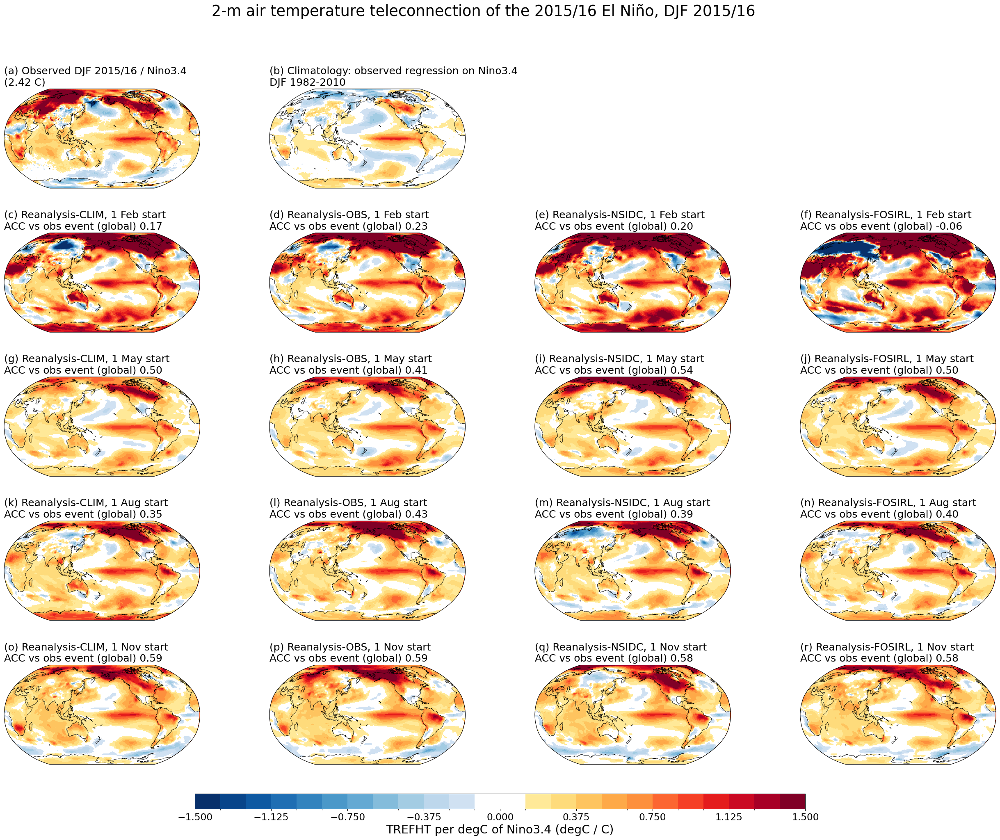

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/4_teleconnections/figures/fig_teleconnection_rtenso2026_nino34_trefht_y2026_djf_202627.png


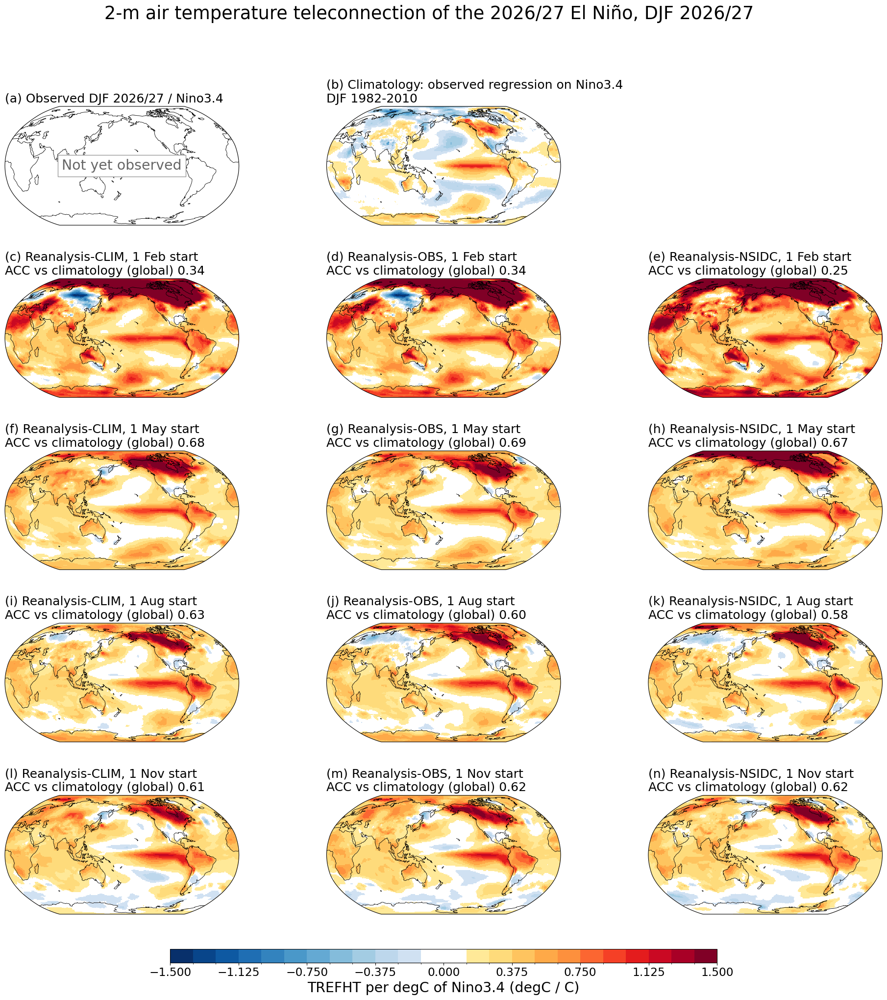

,year,case,start,Nino34_focus,ACC_event_Tropics,ACC_event_NorthAmerica,ACC_event_Global,ACC_obsreg_Tropics,ACC_obsreg_NorthAmerica,ACC_obsreg_Global
0,2015,Reanalysis-CLIM,Feb,1.30,0.241,0.579,0.175,0.496,0.181,0.316
1,2015,Reanalysis-OBS,Feb,1.47,0.378,0.573,0.226,0.606,0.279,0.368
2,2015,Reanalysis-NSIDC,Feb,1.19,0.270,0.375,0.197,0.476,-0.011,0.211
3,2015,Reanalysis-FOSIRL,Feb,0.78,0.007,0.392,-0.058,0.252,0.015,0.127
4,2015,Reanalysis-CLIM,May,3.13,0.652,0.767,0.503,0.837,0.557,0.708
5,2015,Reanalysis-OBS,May,3.09,0.602,0.711,0.405,0.797,0.417,0.678
6,2015,Reanalysis-NSIDC,May,2.91,0.606,0.669,0.542,0.813,0.293,0.641
7,2015,Reanalysis-FOSIRL,May,3.05,0.580,0.804,0.498,0.825,0.592,0.731
8,2015,Reanalysis-CLIM,Aug,2.48,0.479,0.654,0.346,0.675,0.403,0.578
9,2015,Reanalysis-OBS,Aug,2.67,0.590,0.634,0.426,0.731,0.291,0.596


In [6]:
# ---- Figure setup (also used by the Hovmollers below) ----
fontz = 24        # base font size; every other size scales from it
fig_type = "png"  # saved figure type: "png", "pdf" (vector), "eps", "svg", ...
fig_dpi = 300     # resolution of saved raster figures
FIG = {
    "map_panel": (8.0, 4.6),        # inches per map panel (width, height)
    "map_hspace": 0.45,             # vertical gap between map rows (fraction of a panel height)
    "map_top": 0.88,                # top of the map panels (figure fraction); the suptitle sits above
    "map_suptitle_y": 0.97,
    "hov_panel": (6.0, 7.0),        # inches per Hovmoller panel
    "hov_top": 0.93,                # top of the Hovmoller panels (figure fraction); the suptitle sits above
    "hov_suptitle_y": 0.975,
    "hov_lon_tick_step": {"regional": 40, "global": 60},   # degrees between longitude labels
    "hov_lon_tick_rotation": 45,
    "hov_contour_lw": 0.8,          # black contour lines over the shading (negative dashed)
    "hov_clabel": True,             # label every other contour line
    "hov_cbar_orientation": "vertical",
    "hov_cbar_pad": 0.02,           # gap between the panels and the colorbar
    "hov_time_down": True,          # Hovmoller time axis runs from early (top) to late (bottom)
    "suptitle": fontz * 1.1,
    "title": fontz * 0.75,          # panel titles
    "label": fontz * 0.85,          # axis and colorbar labels
    "tick": fontz * 0.7,
    "coast_lw": 0.6,
}
PANEL_LETTERS = "abcdefghijklmnopqrstuvwxyz"


def save_fig(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type))


def add_colorbar(fig, mappable, axes, label, pad=0.04, orientation="horizontal"):
    shrink = 0.6 if orientation == "horizontal" else 0.8
    cbar = fig.colorbar(mappable, ax=axes, orientation=orientation, fraction=0.03 if orientation == "horizontal" else 0.015,
                        pad=pad, shrink=shrink, aspect=40)
    cbar.set_label(label, fontsize=FIG["label"])
    cbar.ax.tick_params(labelsize=FIG["tick"])
    return cbar


def draw_map(fig, da, nrow, ncol, index, title, field, scale=1.0, empty="Not yet observed"):
    """Robinson map in the ESP-Lab style; NaN (e.g. land for SST) is light grey. ``da`` None: an empty
    panel showing ``empty``. Returns (axes, mappable or None)."""
    ax = fig.add_subplot(nrow, ncol, index, projection=ccrs.Robinson(central_longitude=180))
    ax.set_global()
    ax.coastlines(lw=FIG["coast_lw"])
    ax.set_title(title, fontsize=FIG["title"], loc="left")
    if da is None:
        ax.text(0.5, 0.5, empty, transform=ax.transAxes, ha="center", va="center", fontsize=FIG["label"], color="0.4",
                bbox={"facecolor": "white", "edgecolor": "0.6", "pad": 6})
        return ax, None
    ci, cmin, cmax, cmap = MAP_STYLE[field]
    ci, cmin, cmax = ci * scale, cmin * scale, cmax * scale
    levels = np.arange(cmin, cmax + ci / 2, ci)
    cmap = map_cmap(cmap, ci, cmin, cmax)
    values, lon = add_cyclic_point(da.values, coord=da["lon"].values)
    values = np.ma.filled(values, np.nan)  # cartopy wraps pcolormesh only with transparent missing values
    ax.set_facecolor("0.85")
    cntr = ax.pcolormesh(lon, da["lat"].values, values, cmap=cmap, norm=BoundaryNorm(levels, ncolors=cmap.N),
                         shading="nearest", rasterized=True, transform=ccrs.PlateCarree())
    return ax, cntr


scale = MAP_SCALE.get(FIELD, 1.0)
rows = []
for year, ev in EVENTS.items():
    inits = [i for i in ev["init_months"] if any((year, c, i) in event for c in CASES)]
    cases = [c for c in CASES if any((year, c, i) in event for i in inits)]
    if not inits:
        continue
    nrow, ncol = 1 + len(inits), max(2, len(cases))   # observed row, then one row per start (one panel per case)
    fig = plt.figure(figsize=(FIG["map_panel"][0] * ncol, FIG["map_panel"][1] * nrow))
    fig.subplots_adjust(hspace=FIG["map_hspace"], top=FIG["map_top"])
    # (a) the observed event: the direct target of the case panels; (b) the climatological reference
    obs_ev = obs_event[year]
    title = f"(a) Observed {ev['peak_season']['label']} / {INDEX}"
    if obs_ev is not None:
        title += f"\n({obs_event_nino[year]:.2f} C)"
    draw_map(fig, obs_ev, nrow, ncol, 1, title, FIELD, scale)
    _, cntr = draw_map(fig, obs_reg, nrow, ncol, 2,
                       f"(b) Climatology: observed regression on {INDEX}\nDJF {REG_YEARS[0]}-{REG_YEARS[1]}",
                       FIELD, scale)
    k = 2
    for r, init in enumerate(inits, start=1):
        for c, case in enumerate(cases, start=1):
            if (year, case, init) not in event:
                continue
            pattern = event[(year, case, init)]
            title = f"({PANEL_LETTERS[k]}) {case}, 1 {MONTH_NAMES[init]} start\n"
            if obs_ev is not None:
                title += f"ACC vs obs event (global) {float(rc.pattern_acc(pattern, obs_ev, 'Global')):.2f}"
            else:
                title += f"ACC vs climatology (global) {float(rc.pattern_acc(pattern, obs_reg, 'Global')):.2f}"
            draw_map(fig, pattern, nrow, ncol, r * ncol + c, title, FIELD, scale)
            k += 1
            rows.append({"year": year, "case": case, "start": MONTH_NAMES[init],
                         "Nino34_focus": round(float(nino_djf[(year, case, init)].mean()), 2),
                         **{f"ACC_event_{reg}": round(float(rc.pattern_acc(pattern, obs_ev, reg)), 3) if obs_ev is not None else np.nan
                            for reg in TELE_REGIONS},
                         **{f"ACC_obsreg_{reg}": round(float(rc.pattern_acc(pattern, obs_reg, reg)), 3) for reg in TELE_REGIONS}})
    add_colorbar(fig, cntr, fig.axes, f"{FIELD} per degC of {INDEX} ({rc.FIELDS[FIELD]['units']} / C)")
    fig.suptitle(f"{rc.FIELDS[FIELD]['long_name']} teleconnection of the {ev['label']}, {ev['peak_season']['label']}",
                 fontsize=FIG["suptitle"], y=FIG["map_suptitle_y"])
    save_fig(fig, "teleconnection", "rtenso2026", INDEX.replace(".", ""), FIELD, f"y{year}", ev["peak_season"]["label"].replace("/", ""))
    plt.show()

tele_table = pd.DataFrame(rows)
tele_table.to_csv(OUTDIR / f"RTENSO2026_case_{INDEX.replace('.', '')}_{FIELD}_teleconnection_acc.csv", index=False)
tele_table

### Equatorial Hovmollers

Mean over 5S-5N; anomalies as above. One figure per event and field, one row per start, in the CPC monitoring style (shading with black contours, negative dashed). Velocity potential is computed from the anomalous 200-hPa winds (`rc.velocity_potential`); negative (green) is upper-level divergence, favourable for rainfall. Observed panels are blank where there are no observations (U850 and CHI200: ERA5 ends in 2019; TS and OLR: through the latest month).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/4_teleconnections/figures/fig_rtenso2026_hovmoller_ts_y2015.png


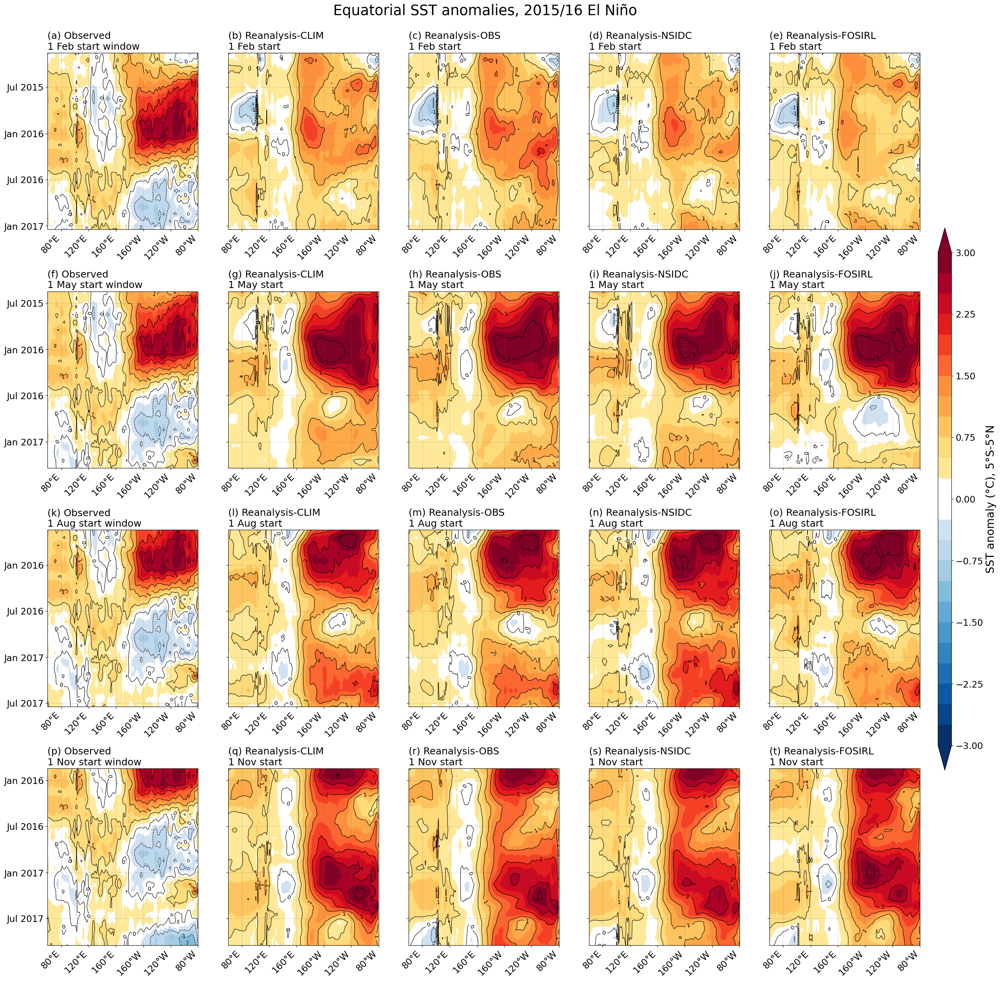

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/4_teleconnections/figures/fig_rtenso2026_hovmoller_u850_y2015.png


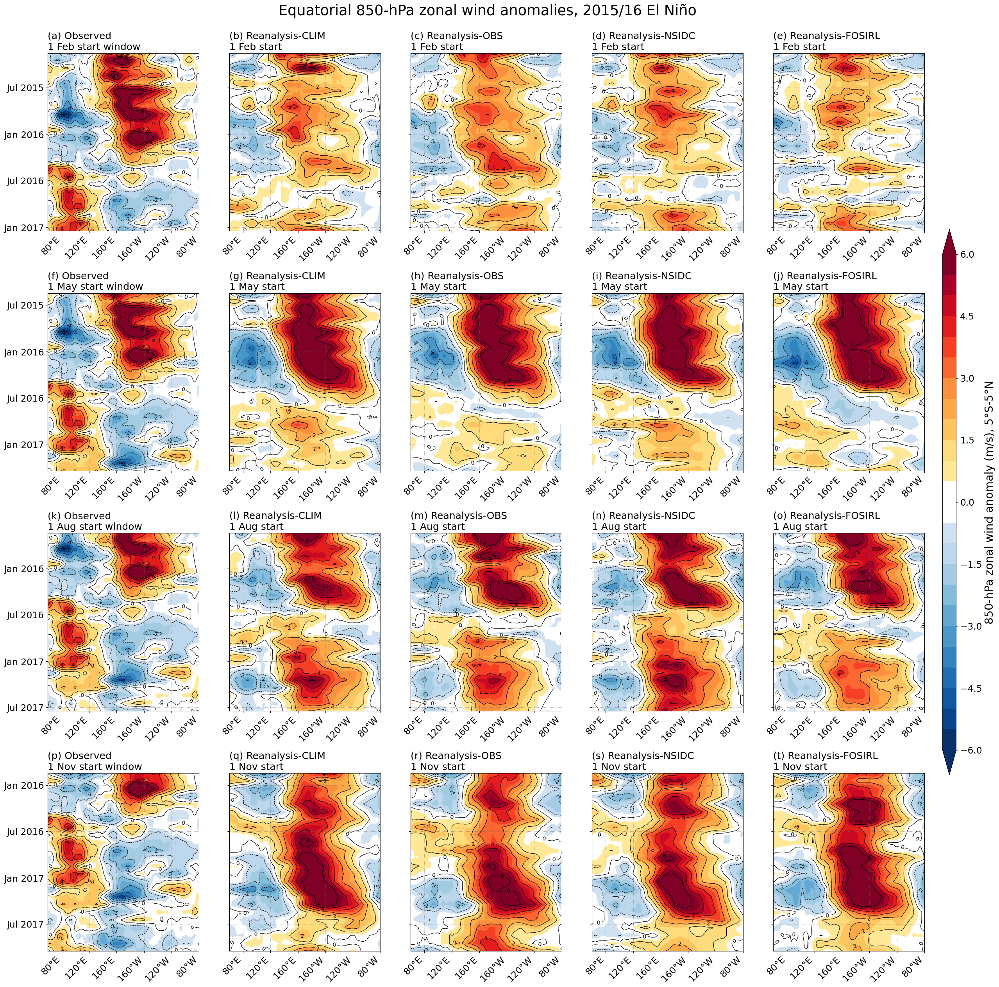

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/4_teleconnections/figures/fig_rtenso2026_hovmoller_flut_y2015.png


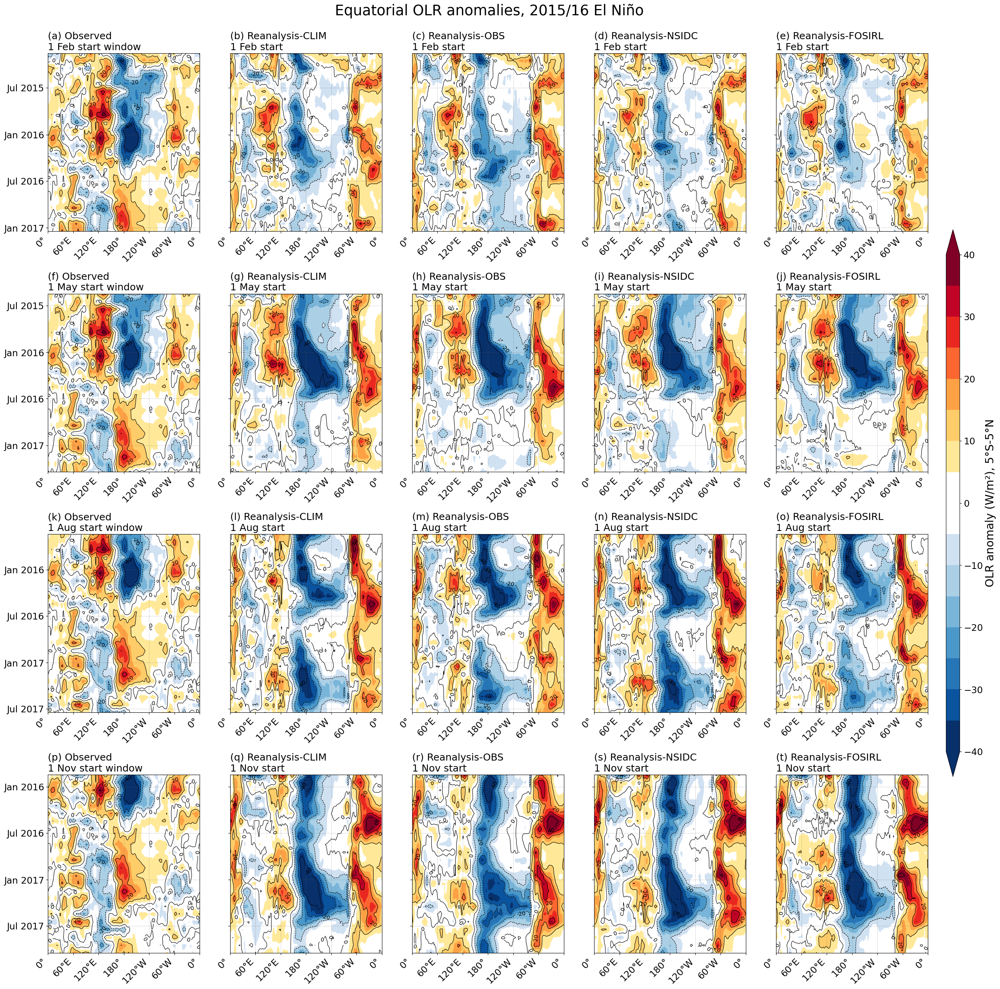

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/4_teleconnections/figures/fig_rtenso2026_hovmoller_chi200_y2015.png


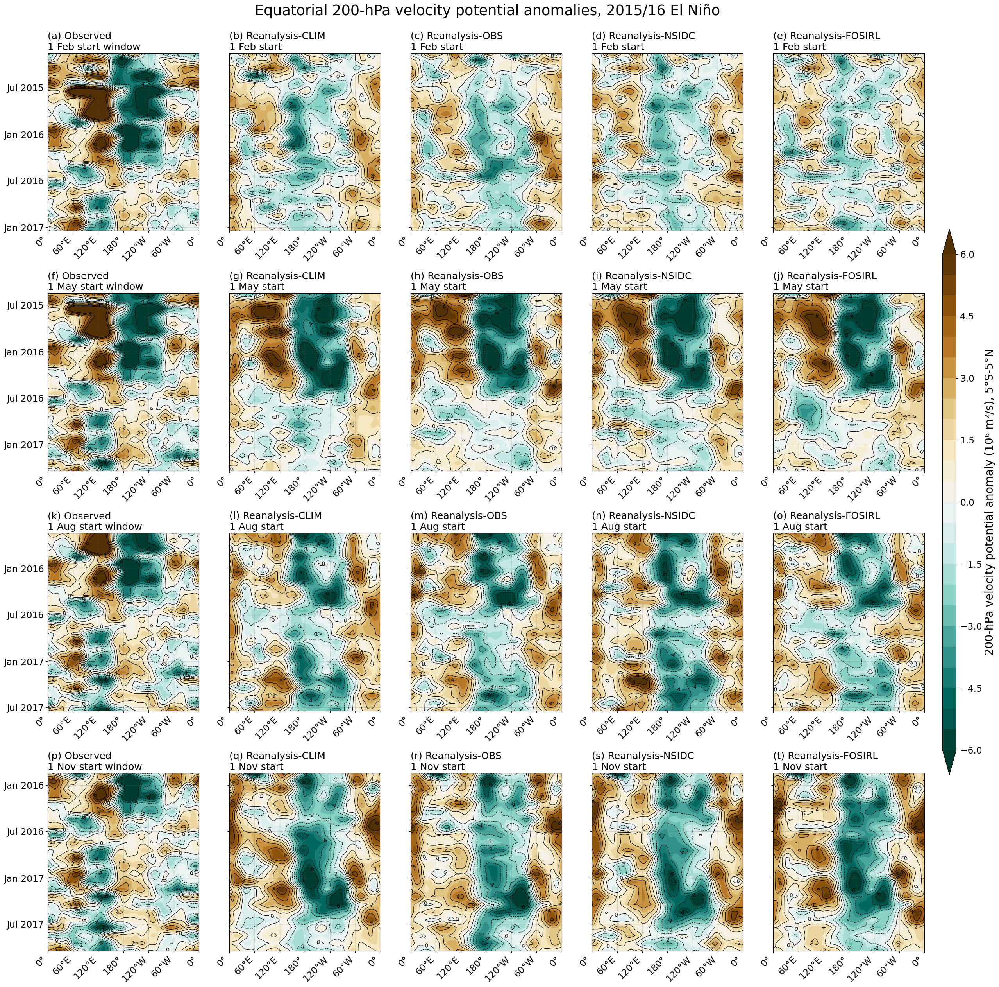

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/4_teleconnections/figures/fig_rtenso2026_hovmoller_ts_y2026.png


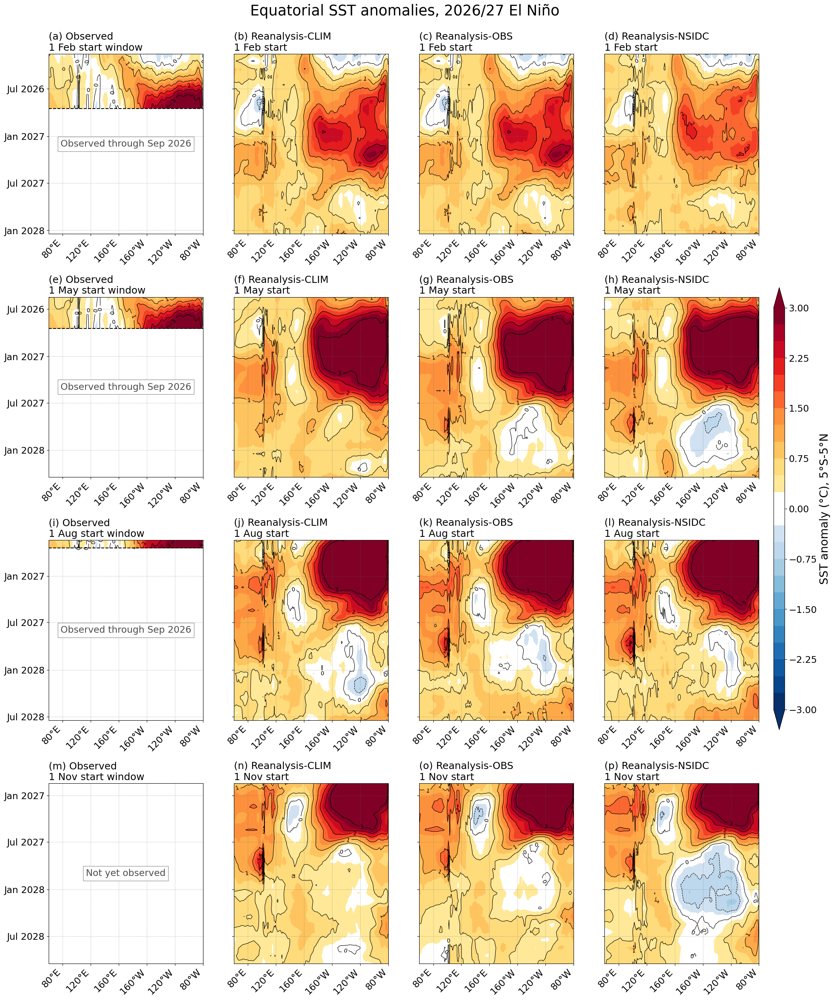

no U850 observations for 2026-2028: no U850 observations after 2019 (ERA5); archive products cover ['FLUT', 'OHC700', 'PRECT', 'SICE']


In [ ]:
%%time
HOV_STYLE = {   # shading interval and range, contour-line interval, colormap, display scale, units
    "TS": {"ci": 0.25, "range": 3.0, "line": 0.5, "cmap": "blue2red", "scale": 1.0, "units": "°C"},
    "U850": {"ci": 0.5, "range": 6.0, "line": 1.0, "cmap": "blue2red", "scale": 1.0, "units": "m/s"},
    "FLUT": {"ci": 5.0, "range": 40.0, "line": 10.0, "cmap": "blue2red", "scale": 1.0, "units": "W/m²"},
    "CHI200": {"ci": 0.5, "range": 6.0, "line": 1.0, "cmap": "BrBG_r", "scale": 1e-6, "units": "10⁶ m²/s"},
}
HOV_NAMES = {"TS": "SST", "U850": "850-hPa zonal wind", "FLUT": "OLR", "CHI200": "200-hPa velocity potential"}
MONTH_ABBR = dict(enumerate(["", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]))


def lon_label(lon):
    lon = lon % 360
    return "0°" if lon == 0 else "180°" if lon == 180 else (f"{lon:g}°E" if lon < 180 else f"{360 - lon:g}°W")


def equatorial(da, domain):
    sub = rc.region_subset(da, [domain[0], domain[1], HOV_LAT[0], HOV_LAT[1]])
    return sub.weighted(rc.area_weights(sub["lat"])).mean("lat")


def hov_obs(hfield, year):
    """Observed anomalies for the event years, or None where no product covers them."""
    if hfield == "CHI200":
        u, v = try_obs_anomaly("U200", (year, year + 2)), try_obs_anomaly("V200", (year, year + 2))
        return None if u is None or v is None else rc.velocity_potential(u, v)
    return try_obs_anomaly(hfield, (year, year + 2), OBS_REFERENCE.get(hfield))


def hov_model(hfield, case, init, year):
    """Ensemble-mean forecast anomalies (lead, lat, lon), or None when the case is missing."""
    def get(field):
        return rc.hindcast_anomaly(CASES[case]["case_prefix"], init, field, year=year, method=CLIM_METHOD, mode=derivation_mode)
    if hfield == "CHI200":
        u, v = get("U200"), get("V200")
        return None if u is None or v is None else rc.velocity_potential(u.mean("member"), v.mean("member"))
    anom = get(hfield)
    if anom is None:
        return None
    if hfield == "TS":   # SST only, like the observations (the domain crosses the Maritime Continent)
        anom = anom.where(rc.land_fraction() < 0.5)
    return anom.mean("member")


def draw_hov(ax, lon, times, data, levels, cmap, line_ci):
    """CPC-style Hovmoller: shading plus black contour lines (negative dashed), every other one labelled."""
    y = to_datetime(times)
    cf = ax.contourf(lon, y, data, levels=levels, cmap=cmap, extend="both")
    cs = ax.contour(lon, y, data, levels=np.arange(levels[0], levels[-1] + line_ci / 2, line_ci), colors="k",
                    linewidths=FIG["hov_contour_lw"])
    if FIG["hov_clabel"] and len(cs.levels):
        ax.clabel(cs, cs.levels[::2], fmt="%g", fontsize=FIG["tick"] * 0.6, inline=True)
    return cf


def format_hov(ax, domain, title):
    ax.set_title(title, fontsize=FIG["title"], loc="left")
    ax.tick_params(labelsize=FIG["tick"])
    ax.yaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.yaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    step = FIG["hov_lon_tick_step"]["global" if domain[1] - domain[0] > 240 else "regional"]
    ticks = np.arange(np.ceil(domain[0] / step) * step, domain[1] + 0.1, step)
    ax.set_xlim(*domain)
    ax.set_xticks(ticks)
    ax.set_xticklabels([lon_label(t) for t in ticks], rotation=FIG["hov_lon_tick_rotation"], ha="right")
    ax.grid(ls=":", color="0.4", alpha=0.6)
    lo, hi = sorted(ax.get_ylim())   # set, not toggled: the panels in a row share the y axis
    ax.set_ylim((hi, lo) if FIG["hov_time_down"] else (lo, hi))


for year, ev in EVENTS.items():
    inits = ev["init_months"]
    cases = [c for c in CASES if any((year, c, i) in event for i in inits)] or list(CASES)
    for hfield in HOV_FIELDS:
        style, domain = HOV_STYLE[hfield], HOV_DOMAIN[hfield]
        obs_anom = hov_obs(hfield, year)
        obs_h = (equatorial(obs_anom, domain) * style["scale"]).load() if obs_anom is not None else None
        levels = np.arange(-style["range"], style["range"] + style["ci"] / 2, style["ci"])
        cmap = map_cmap(style["cmap"], style["ci"], -style["range"], style["range"])
        panels = ["Observed"] + cases
        fig, axes = plt.subplots(len(inits), len(panels), figsize=(FIG["hov_panel"][0] * len(panels), FIG["hov_panel"][1] * len(inits)),
                                 sharey="row", squeeze=False)
        cf = None
        for row, init in enumerate(inits):
            times = None
            for col, name in enumerate(panels[1:], start=1):
                ax = axes[row, col]
                anom = hov_model(hfield, name, init, year) if rc.has_start(name, year, init) else None
                if anom is None:
                    ax.set_visible(False)
                    continue
                h = (equatorial(anom, domain) * style["scale"]).load()
                times = h["time"].values
                cf = draw_hov(ax, h["lon"], times, h.transpose("lead", "lon"), levels, cmap, style["line"])
                format_hov(ax, domain, f"({PANEL_LETTERS[row * len(panels) + col]}) {name}\n1 {MONTH_NAMES[init]} start")
            ax = axes[row, 0]
            if times is None:
                ax.set_visible(False)
                continue
            title = f"({PANEL_LETTERS[row * len(panels)]}) Observed\n1 {MONTH_NAMES[init]} start window"
            if obs_h is not None:
                lead = xr.DataArray(np.zeros(len(times)), dims="lead", coords={"lead": np.arange(len(times)), "time": ("lead", times)})
                o = rc.match_obs(lead, obs_h)   # NaN past the last observation
                observed = o.notnull().any("lon").values
                if observed.sum() >= 2:
                    draw_hov(ax, o["lon"], times, o.transpose("lead", "lon"), levels, cmap, style["line"])
                if not observed.all():   # observations end inside the window
                    last = times[observed.nonzero()[0][-1]] if observed.any() else None
                    note = f"Observed through {MONTH_ABBR[last.month]} {last.year}" if last is not None else "Not yet observed"
                    if last is not None and observed.sum() >= 2:
                        ax.axhline(to_datetime(last)[0], color="k", ls="--", lw=1.5)
                    ax.text(0.5, 0.5, note, transform=ax.transAxes, ha="center", va="center",
                            fontsize=FIG["tick"], color="0.3", bbox={"facecolor": "white", "edgecolor": "0.6", "pad": 5})
            else:
                ax.text(0.5, 0.5, "No observations", transform=ax.transAxes, ha="center", va="center",
                        fontsize=FIG["label"], color="0.4")
            format_hov(ax, domain, title)
        if cf is None:
            plt.close(fig)
            continue
        fig.subplots_adjust(hspace=0.35, top=FIG["hov_top"])
        add_colorbar(fig, cf, axes, f"{HOV_NAMES[hfield]} anomaly ({style['units']}), {abs(HOV_LAT[0]):.0f}°S-{HOV_LAT[1]:.0f}°N",
                     pad=FIG["hov_cbar_pad"], orientation=FIG["hov_cbar_orientation"])
        fig.suptitle(f"Equatorial {HOV_NAMES[hfield]} anomalies, {ev['label']}", fontsize=FIG["suptitle"], y=FIG["hov_suptitle_y"])
        save_fig(fig, "rtenso2026", "hovmoller", hfield, f"y{year}")
        plt.show()